In [1]:

from pathlib import Path
import random
import numpy as np
import torch
import timm

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Project configuration
DATA_DIR = Path.cwd()
SPLIT_FILE = DATA_DIR / "dataset_split.csv"

MODEL_NAME = "tiny_vit_11m_224.in1k"

BASELINE_CHECKPOINT = (
    DATA_DIR
    / "results"
    / "tinyvit_11m"
    / "checkpoints"
    / "tinyvit_11m_best.pth"
)

RESULTS_DIR = DATA_DIR / "results" / "tinyvit_11m_finetune"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

assert SPLIT_FILE.exists()
assert BASELINE_CHECKPOINT.exists()

# 3. Reconstruct model without downloading weights
model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=3
)

# 4. Load best head-only checkpoint
checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["model_name"] == MODEL_NAME

model.load_state_dict(checkpoint["model_state_dict"])

baseline_f1 = float(checkpoint["val_macro_f1"])

print("Loaded checkpoint epoch:", checkpoint["epoch"])
print(f"Baseline macro-F1: {baseline_f1:.4f}")

# 5. Inspect the architecture
print("\nTINYVIT STAGES")
print("-" * 55)

for i, stage in enumerate(model.stages):
    params = sum(p.numel() for p in stage.parameters())
    print(
        f"Stage {i+1}: "
        f"{type(stage).__name__} | "
        f"{params:,} parameters"
    )

# 6. Freeze everything
for param in model.parameters():
    param.requires_grad = False

# 7. Unfreeze the entire FINAL stage
for param in model.stages[-1].parameters():
    param.requires_grad = True

# 8. Unfreeze classification layer
for param in model.head.fc.parameters():
    param.requires_grad = True

# 9. Move to GPU
model = model.to(DEVICE)

# 10. Keep normalization and stochastic layers stable
model.eval()

# TinyViT caches relative attention biases in eval mode.
# Put trainable attention modules into training mode
# so their biases are recalculated for each forward pass.
for block in model.stages[-1].blocks:
    block.attn.train()

# 11. Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

stage_params = sum(
    p.numel() for p in model.stages[-1].parameters()
)

head_params = sum(
    p.numel() for p in model.head.fc.parameters()
)

assert trainable_params == stage_params + head_params

print("\nFINE-TUNING CONFIGURATION")
print("-" * 55)

print("Device:", DEVICE)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params-trainable_params:,}")

print("\nTrainable components:")
print(f"  Final stage: {stage_params:,}")
print(f"  Classification layer: {head_params:,}")
print(f"  Attention blocks: {len(model.stages[-1].blocks)}")

print("\nAttention training mode:",
      all(b.attn.training for b in model.stages[-1].blocks))

print("\nResults directory:", RESULTS_DIR)
print("Setup complete!")


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded checkpoint epoch: 9
Baseline macro-F1: 0.9396

TINYVIT STAGES
-------------------------------------------------------
Stage 1: ConvLayer | 72,448 parameters
Stage 2: TinyVitStage | 426,248 parameters
Stage 3: TinyVitStage | 4,867,008 parameters
Stage 4: TinyVitStage | 5,161,884 parameters

FINE-TUNING CONFIGURATION
-------------------------------------------------------
Device: mps
Total parameters: 10,549,319
Trainable parameters: 5,163,231
Frozen parameters: 5,386,088

Trainable components:
  Final stage: 5,161,884
  Classification layer: 1,347
  Attention blocks: 2

Attention training mode: True

Results directory: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_11m_finetune
Setup complete!


In [2]:

import csv
from collections import Counter
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# 1. Class mapping
CLASSES = ["Brittle", "Ductile", "Mixed"]

class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

# Verify consistency with saved checkpoint
assert checkpoint["class_to_idx"] == class_to_idx

# 2. Load the original dataset split
with open(SPLIT_FILE, "r", encoding="utf-8-sig") as f:
    split_records = list(csv.DictReader(f))

train_records = [
    r for r in split_records if r["split"] == "train"
]

val_records = [
    r for r in split_records if r["split"] == "validation"
]

test_records = [
    r for r in split_records if r["split"] == "test"
]

# 3. Identical image preprocessing
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 4. SEM dataset
class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = data_dir
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]

        image_path = (
            self.data_dir / row["label"] / row["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["label"]]

        return image, label

# 5. Create datasets
train_dataset = SEMDataset(
    train_records, DATA_DIR, train_transform
)

val_dataset = SEMDataset(
    val_records, DATA_DIR, eval_transform
)

test_dataset = SEMDataset(
    test_records, DATA_DIR, eval_transform
)

# 6. DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# 7. Verify counts and group separation
train_counts = Counter(r["label"] for r in train_records)

assert len(train_dataset) == 1402
assert len(val_dataset) == 280
assert len(test_dataset) == 279

train_groups = {r["group"] for r in train_records}
val_groups = {r["group"] for r in val_records}
test_groups = {r["group"] for r in test_records}

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# 8. Verify a training batch
images, labels = next(iter(train_loader))

assert images.shape == (16, 3, 224, 224)

print("TINYVIT FINE-TUNING DATASET")
print("-" * 50)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Reserved test images:", len(test_dataset))

print("\nTraining class distribution:")
for cls in CLASSES:
    print(f"  {cls}: {train_counts[cls]}")

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\nTraining groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Test groups:", len(test_groups))

print("\nImage batch:", images.shape)
print("Label batch:", labels.shape)

print("\nDataset verification successful!")


TINYVIT FINE-TUNING DATASET
--------------------------------------------------
Training images: 1402
Validation images: 280
Reserved test images: 279

Training class distribution:
  Brittle: 589
  Ductile: 711
  Mixed: 102

Training batches: 88
Validation batches: 18

Training groups: 147
Validation groups: 28
Test groups: 31

Image batch: torch.Size([16, 3, 224, 224])
Label batch: torch.Size([16])

Dataset verification successful!


In [3]:

import torch.nn as nn

# 1. Calculate class weights
num_samples = len(train_records)
num_classes = len(CLASSES)

class_weights = torch.tensor(
    [
        num_samples / (num_classes * train_counts[cls])
        for cls in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

# 2. Weighted cross-entropy
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# 3. Differential learning rates
STAGE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4

# 4. Optimizer
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.stages[-1].parameters(),
            "lr": STAGE_LR
        },
        {
            "params": model.head.fc.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

# 5. Verify optimized parameters
optimized_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert optimized_params == trainable_params
assert trainable_params == 5_163_231

# 6. Verify attention configuration
attention_blocks = [
    block.attn
    for block in model.stages[-1].blocks
]

assert all(attn.training for attn in attention_blocks)

# 7. Test gradient flow using one batch
# No optimizer step: this does NOT modify model weights.
optimizer.zero_grad(set_to_none=True)

images, labels = next(iter(train_loader))

images = images.to(DEVICE)
labels = labels.to(DEVICE)

outputs = model(images)
loss = criterion(outputs, labels)

loss.backward()

# Verify gradients reach the attention layers
first_attention = attention_blocks[0]

bias_grad = first_attention.attention_biases.grad
qkv_grad = first_attention.qkv.weight.grad

assert bias_grad is not None, (
    "Attention bias gradient is missing"
)

assert qkv_grad is not None, (
    "Attention QKV gradient is missing"
)

assert torch.isfinite(bias_grad).all().item()
assert torch.isfinite(qkv_grad).all().item()

bias_grad_norm = bias_grad.norm().item()
qkv_grad_norm = qkv_grad.norm().item()

# Clear diagnostic gradients before actual training
optimizer.zero_grad(set_to_none=True)

# 8. Print configuration
print("TINYVIT-11M FINE-TUNING CONFIGURATION")
print("=" * 55)

print("\nCLASS WEIGHTS")
for cls, weight in zip(CLASSES, class_weights):
    print(f"{cls}: {weight.item():.4f}")

print("\nOPTIMIZER")
print("Type:", optimizer.__class__.__name__)
print("Final stage learning rate:", STAGE_LR)
print("Classification learning rate:", HEAD_LR)
print("Weight decay:", WEIGHT_DECAY)
print("Optimized parameters:", f"{optimized_params:,}")

print("\nGRADIENT VERIFICATION")
print(f"Diagnostic loss: {loss.item():.4f}")
print(f"Attention bias gradient norm: {bias_grad_norm:.6f}")
print(f"Attention QKV gradient norm: {qkv_grad_norm:.6f}")

print("\nAttention gradient flow verified!")
print("Model weights unchanged by diagnostic.")
print("Ready for fine-tuning!")


TINYVIT-11M FINE-TUNING CONFIGURATION

CLASS WEIGHTS
Brittle: 0.7934
Ductile: 0.6573
Mixed: 4.5817

OPTIMIZER
Type: AdamW
Final stage learning rate: 1e-05
Classification learning rate: 0.0001
Weight decay: 0.0001
Optimized parameters: 5,163,231

GRADIENT VERIFICATION
Diagnostic loss: 0.1669
Attention bias gradient norm: 0.008427
Attention QKV gradient norm: 1.279774

Attention gradient flow verified!
Model weights unchanged by diagnostic.
Ready for fine-tuning!


In [4]:

import time
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# 1. Training configuration
MAX_EPOCHS = 10
PATIENCE = 4

history_ft = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_f1": [],
    "val_mixed_recall": [],
    "epoch_time": []
}

# Start from our best head-only result
best_f1 = baseline_f1
best_epoch = 0
epochs_without_improvement = 0

checkpoint_path = (
    CHECKPOINT_DIR / "tinyvit_11m_finetuned_best.pth"
)

# 2. Helper: save checkpoint
def save_checkpoint(epoch, macro_f1):

    torch.save({
        "model_state_dict": {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        },
        "epoch": epoch,
        "val_macro_f1": float(macro_f1),
        "class_to_idx": class_to_idx,
        "model_name": MODEL_NAME,
        "experiment": "final_stage_finetuning"
    }, checkpoint_path)


# 3. Save initial checkpoint as fallback
# If fine-tuning does not help, preserve baseline.
save_checkpoint(
    epoch=0,
    macro_f1=baseline_f1
)

print("FINE-TUNING TINYVIT-11M")
print("=" * 75)

print(f"Starting Macro-F1: {baseline_f1:.4f}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Early stopping patience: {PATIENCE}")
print()

# 4. Training loop
for epoch in range(MAX_EPOCHS):

    if DEVICE.type == "mps":
        torch.mps.synchronize()

    start_time = time.perf_counter()

    # Keep pretrained BatchNorm statistics fixed
    model.eval()

    # IMPORTANT:
    # Reactivate trainable attention layers so TinyViT
    # computes relative attention biases with gradients.
    for block in model.stages[-1].blocks:
        block.attn.train()

    assert all(
        block.attn.training
        for block in model.stages[-1].blocks
    )

    train_loss_total = 0.0
    train_samples = 0

    # 5. Training batches
    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        outputs = model(images)

        # Weighted cross-entropy
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Clip gradients for stability
        torch.nn.utils.clip_grad_norm_(
            (p for p in model.parameters()
             if p.requires_grad),
            max_norm=1.0
        )

        # Update final stage and classification layer
        optimizer.step()

        train_loss_total += (
            loss.item() * labels.size(0)
        )
        train_samples += labels.size(0)

    train_loss = train_loss_total / train_samples

    # 6. Validation
    # Switch all attention modules to evaluation mode.
    model.eval()

    val_loss_total = 0.0
    val_samples = 0

    all_labels = []
    all_predictions = []

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += (
                loss.item() * labels.size(0)
            )
            val_samples += labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(
                labels.cpu().tolist()
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

    val_loss = val_loss_total / val_samples

    # 7. Validation metrics
    val_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    val_mixed_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    val_mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    # 8. Measure epoch duration
    if DEVICE.type == "mps":
        torch.mps.synchronize()

    elapsed = time.perf_counter() - start_time

    # 9. Record history
    history_ft["train_loss"].append(train_loss)
    history_ft["val_loss"].append(val_loss)
    history_ft["val_accuracy"].append(val_accuracy)
    history_ft["val_macro_f1"].append(val_macro_f1)
    history_ft["val_mixed_f1"].append(val_mixed_f1)
    history_ft["val_mixed_recall"].append(
        val_mixed_recall
    )
    history_ft["epoch_time"].append(elapsed)

    # 10. Save best model by validation Macro-F1
    if val_macro_f1 > best_f1 + 1e-6:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        save_checkpoint(
            epoch=best_epoch,
            macro_f1=best_f1
        )

        epochs_without_improvement = 0
        status = "NEW BEST"

    else:

        epochs_without_improvement += 1
        status = "No improvement"

    # 11. Print results
    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.3f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Mixed F1: {val_mixed_f1:.3f} | "
        f"Mixed Recall: {val_mixed_recall:.3f} | "
        f"Time: {elapsed:.1f}s | "
        f"{status}"
    )

    # 12. Early stopping
    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break


# 13. Restore best checkpoint
best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# 14. Final summary
print("\nFINE-TUNING COMPLETED")
print("=" * 60)

print("Best fine-tuning epoch:", best_epoch)

print(
    f"TinyViT head-only Macro-F1:   {baseline_f1:.4f}"
)

print(
    f"TinyViT fine-tuned Macro-F1: {best_f1:.4f}"
)

print(
    f"Improvement:                "
    f"{best_f1 - baseline_f1:+.4f}"
)

print("\nREFERENCE MODELS")
print("ResNet-18 head-only:    0.9434")
print("ResNet-18 fine-tuned:   0.9525")
print("DeiT-Tiny fine-tuned:   0.8954")

print(
    "\nAverage epoch time:",
    f"{np.mean(history_ft['epoch_time']):.1f}s"
)

print("\nCheckpoint saved:", checkpoint_path)


FINE-TUNING TINYVIT-11M
Starting Macro-F1: 0.9396
Maximum epochs: 10
Early stopping patience: 4

Epoch 01/10 | Train Loss: 0.1994 | Val Loss: 0.0501 | Accuracy: 0.986 | Macro-F1: 0.9620 | Mixed F1: 0.900 | Mixed Recall: 0.857 | Time: 10.8s | NEW BEST
Epoch 02/10 | Train Loss: 0.1616 | Val Loss: 0.0417 | Accuracy: 0.986 | Macro-F1: 0.9695 | Mixed F1: 0.927 | Mixed Recall: 0.905 | Time: 10.4s | NEW BEST
Epoch 03/10 | Train Loss: 0.1304 | Val Loss: 0.0496 | Accuracy: 0.971 | Macro-F1: 0.9323 | Mixed F1: 0.826 | Mixed Recall: 0.905 | Time: 10.3s | No improvement
Epoch 04/10 | Train Loss: 0.0927 | Val Loss: 0.0440 | Accuracy: 0.979 | Macro-F1: 0.9494 | Mixed F1: 0.870 | Mixed Recall: 0.952 | Time: 10.3s | No improvement
Epoch 05/10 | Train Loss: 0.1275 | Val Loss: 0.0412 | Accuracy: 0.986 | Macro-F1: 0.9630 | Mixed F1: 0.905 | Mixed Recall: 0.905 | Time: 10.3s | No improvement
Epoch 06/10 | Train Loss: 0.2022 | Val Loss: 0.0348 | Accuracy: 0.989 | Macro-F1: 0.9718 | Mixed F1: 0.927 | Mixed 


TinyViT Head-Only
              precision    recall  f1-score   support

     Brittle     1.0000    0.9915    0.9957       117
     Ductile     0.9857    0.9718    0.9787       142
       Mixed     0.7917    0.9048    0.8444        21

    accuracy                         0.9750       280
   macro avg     0.9258    0.9560    0.9396       280
weighted avg     0.9771    0.9750    0.9757       280


TinyViT Fine-Tuned
              precision    recall  f1-score   support

     Brittle     1.0000    1.0000    1.0000       117
     Ductile     0.9860    0.9930    0.9895       142
       Mixed     0.9500    0.9048    0.9268        21

    accuracy                         0.9893       280
   macro avg     0.9787    0.9659    0.9721       280
weighted avg     0.9892    0.9893    0.9892       280



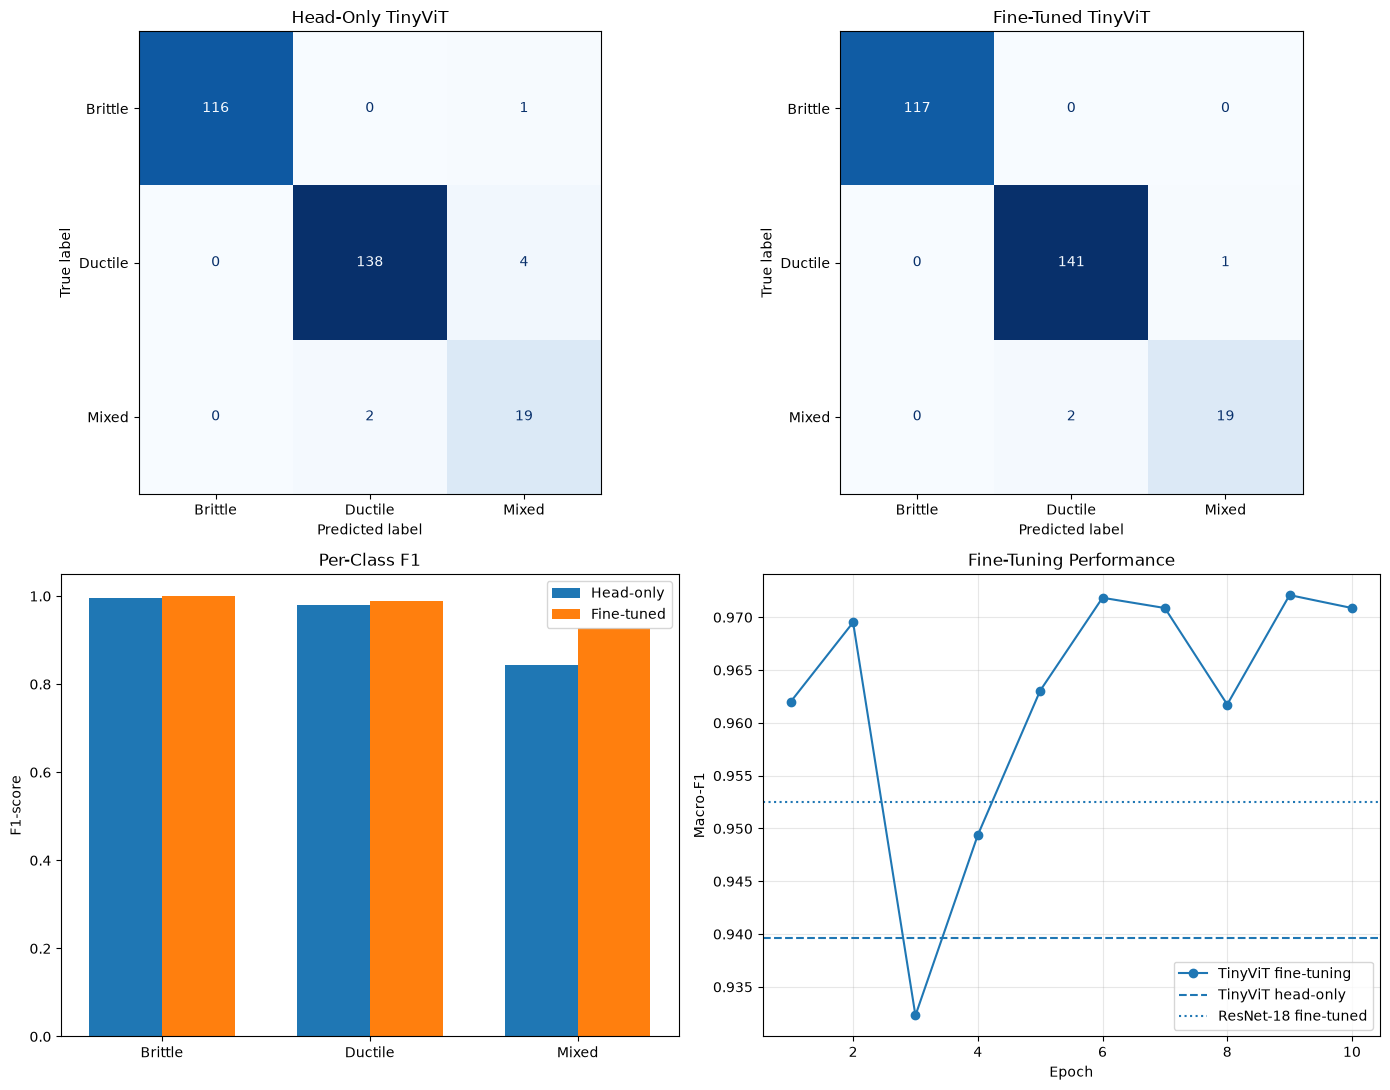


PREDICTION CHANGES
-------------------------------------------------------
Corrected errors: 4
New errors: 0
Changed but still wrong: 0

CHANGED IMAGES
100Cr6_AR_06_10.png | Actual: Brittle | Before: Mixed | After: Brittle
316L_AR_04_7.png | Actual: Ductile | Before: Mixed | After: Ductile
316L_AR_21_20.png | Actual: Ductile | Before: Mixed | After: Ductile
316L_AR_23_13.png | Actual: Ductile | Before: Mixed | After: Ductile

REMAINING FINE-TUNED ERRORS
-------------------------------------------------------
304_H2_04_25.png | Actual: Ductile | Predicted: Mixed
316L_AR_04_15.png | Actual: Mixed | Predicted: Ductile
mX65_H2_26_29.png | Actual: Mixed | Predicted: Ductile

Remaining errors: 3
Plot saved: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_11m_finetune/plots/tinyvit_finetuning_comparison.png


In [5]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Reconstruct head-only TinyViT from saved checkpoint
baseline_model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=3
)

baseline_model.load_state_dict(
    checkpoint["model_state_dict"]
)

baseline_model = baseline_model.to(DEVICE)
baseline_model.eval()

# Fine-tuned model was restored to best checkpoint
model.eval()

# 2. Predict on identical validation images
def evaluate_model(net, loader):
    actual = []
    predicted = []

    net.eval()

    with torch.inference_mode():
        for images, labels in loader:
            outputs = net(images.to(DEVICE))
            preds = outputs.argmax(dim=1)

            actual.extend(labels.tolist())
            predicted.extend(preds.cpu().tolist())

    return actual, predicted

y_true, baseline_preds = evaluate_model(
    baseline_model, val_loader
)

y_true_ft, finetuned_preds = evaluate_model(
    model, val_loader
)

assert y_true == y_true_ft
assert len(y_true) == len(val_records)

# 3. Print classification reports
for name, predictions in [
    ("TinyViT Head-Only", baseline_preds),
    ("TinyViT Fine-Tuned", finetuned_preds)
]:
    print("\n" + name)
    print("=" * 55)

    print(classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))

# 4. Class-level F1
baseline_class_f1 = f1_score(
    y_true, baseline_preds,
    labels=[0, 1, 2],
    average=None,
    zero_division=0
)

finetuned_class_f1 = f1_score(
    y_true, finetuned_preds,
    labels=[0, 1, 2],
    average=None,
    zero_division=0
)

# 5. Plot results
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, name, predictions in [
    (axes[0, 0], "Head-Only TinyViT", baseline_preds),
    (axes[0, 1], "Fine-Tuned TinyViT", finetuned_preds)
]:
    cm = confusion_matrix(
        y_true, predictions, labels=[0, 1, 2]
    )

    ConfusionMatrixDisplay(
        cm, display_labels=CLASSES
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

# Per-class F1
x = np.arange(len(CLASSES))
width = 0.35

axes[1, 0].bar(
    x - width/2, baseline_class_f1,
    width, label="Head-only"
)

axes[1, 0].bar(
    x + width/2, finetuned_class_f1,
    width, label="Fine-tuned"
)

axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(CLASSES)
axes[1, 0].set_ylim(0, 1.05)
axes[1, 0].set_title("Per-Class F1")
axes[1, 0].set_ylabel("F1-score")
axes[1, 0].legend()

# Fine-tuning history
epochs = np.arange(
    1, len(history_ft["val_macro_f1"]) + 1
)

axes[1, 1].plot(
    epochs,
    history_ft["val_macro_f1"],
    marker="o",
    label="TinyViT fine-tuning"
)

axes[1, 1].axhline(
    baseline_f1,
    linestyle="--",
    label="TinyViT head-only"
)

axes[1, 1].axhline(
    0.9525,
    linestyle=":",
    label="ResNet-18 fine-tuned"
)

axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Macro-F1")
axes[1, 1].set_title("Fine-Tuning Performance")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()

plot_path = PLOTS_DIR / "tinyvit_finetuning_comparison.png"

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 6. Identify changed predictions
corrected = []
new_errors = []
other_changes = []

for i, (actual, before, after) in enumerate(
    zip(y_true, baseline_preds, finetuned_preds)
):
    if before == after:
        continue

    if before != actual and after == actual:
        corrected.append(i)

    elif before == actual and after != actual:
        new_errors.append(i)

    else:
        other_changes.append(i)

print("\nPREDICTION CHANGES")
print("-" * 55)

print("Corrected errors:", len(corrected))
print("New errors:", len(new_errors))
print("Changed but still wrong:", len(other_changes))

print("\nCHANGED IMAGES")
for i in corrected + new_errors + other_changes:
    print(
        f"{val_records[i]['filename']} | "
        f"Actual: {CLASSES[y_true[i]]} | "
        f"Before: {CLASSES[baseline_preds[i]]} | "
        f"After: {CLASSES[finetuned_preds[i]]}"
    )

print("\nREMAINING FINE-TUNED ERRORS")
print("-" * 55)

remaining_errors = [
    i for i, (actual, pred) in enumerate(
        zip(y_true, finetuned_preds)
    )
    if actual != pred
]

for i in remaining_errors:
    print(
        f"{val_records[i]['filename']} | "
        f"Actual: {CLASSES[y_true[i]]} | "
        f"Predicted: {CLASSES[finetuned_preds[i]]}"
    )

print(f"\nRemaining errors: {len(remaining_errors)}")
print("Plot saved:", plot_path)


In [6]:

import json
import numpy as np
from datetime import datetime, timezone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Verify prediction alignment
assert y_true == [
    class_to_idx[r["label"]] for r in val_records
]

# 2. Calculate metrics from actual predictions
def calculate_metrics(actual, predicted):
    return {
        "accuracy": float(accuracy_score(actual, predicted)),
        "macro_f1": float(f1_score(
            actual, predicted,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        )),
        "classification_report": classification_report(
            actual, predicted,
            labels=[0, 1, 2],
            target_names=CLASSES,
            output_dict=True,
            zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            actual, predicted,
            labels=[0, 1, 2]
        ).tolist()
    }

head_only_metrics = calculate_metrics(
    y_true, baseline_preds
)

finetuned_metrics = calculate_metrics(
    y_true, finetuned_preds
)

# 3. Record every changed prediction
prediction_changes = []

for i, (actual, before, after) in enumerate(
    zip(y_true, baseline_preds, finetuned_preds)
):
    if before == after:
        continue

    if before != actual and after == actual:
        status = "corrected"
    elif before == actual and after != actual:
        status = "new_error"
    else:
        status = "changed_still_wrong"

    prediction_changes.append({
        "filename": val_records[i]["filename"],
        "actual": CLASSES[actual],
        "before": CLASSES[before],
        "after": CLASSES[after],
        "status": status
    })

# 4. Record remaining errors
remaining_errors = [
    {
        "filename": val_records[i]["filename"],
        "actual": CLASSES[actual],
        "predicted": CLASSES[predicted]
    }
    for i, (actual, predicted) in enumerate(
        zip(y_true, finetuned_preds)
    )
    if actual != predicted
]

# 5. Build experiment summary
summary = {
    "experiment": "TinyViT-11M SEM Fracture Classification",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "architecture": {
        "name": MODEL_NAME,
        "type": "Hybrid CNN-Vision Transformer",
        "pretraining": "ImageNet-1K",
        "total_parameters": 10_549_319,
        "head_only_trainable_parameters": 1347,
        "finetuning_trainable_parameters": 5_163_231,
        "finetuned_stage": 4,
        "input_size": [224, 224]
    },

    "dataset": {
        "split_file": "dataset_split.csv",
        "train": len(train_records),
        "validation": len(val_records),
        "test_reserved": len(test_records),
        "classes": CLASSES,
        "train_class_counts": dict(train_counts),
        "batch_size": BATCH_SIZE,
        "resize_interpolation": "bilinear",
        "normalization": "ImageNet mean/std",
        "augmentation": [
            "RandomHorizontalFlip",
            "RandomVerticalFlip"
        ],
        "grouping": "Filename-derived groups",
        "train_groups": len(train_groups),
        "validation_groups": len(val_groups),
        "test_groups": len(test_groups)
    },

    "head_only": {
        "best_epoch": int(checkpoint["epoch"]),
        "checkpoint": str(BASELINE_CHECKPOINT),
        **head_only_metrics
    },

    "finetuning_configuration": {
        "initial_checkpoint": str(BASELINE_CHECKPOINT),
        "trainable_components": [
            "stages.3",
            "head.fc"
        ],
        "stage_learning_rate": STAGE_LR,
        "head_learning_rate": HEAD_LR,
        "weight_decay": WEIGHT_DECAY,
        "optimizer": "AdamW",
        "loss": "Class-weighted CrossEntropyLoss",
        "class_weights": class_weights.cpu().tolist(),
        "gradient_clip_max_norm": 1.0,
        "maximum_epochs": MAX_EPOCHS,
        "early_stopping_patience": PATIENCE,
        "epochs_completed": len(history_ft["train_loss"]),
        "best_epoch": int(best_checkpoint["epoch"]),
        "best_checkpoint": str(checkpoint_path),
        "random_seed": SEED
    },

    "fine_tuned": finetuned_metrics,

    "comparison": {
        "macro_f1_improvement": (
            finetuned_metrics["macro_f1"]
            - head_only_metrics["macro_f1"]
        ),
        "accuracy_improvement": (
            finetuned_metrics["accuracy"]
            - head_only_metrics["accuracy"]
        ),
        "corrected_errors": len(corrected),
        "new_errors": len(new_errors),
        "other_changes": len(other_changes),
        "prediction_changes": prediction_changes,
        "remaining_errors": remaining_errors
    },

    "finetuning_history": history_ft,

    "reference_models": {
        "resnet18_head_only_macro_f1": 0.9434,
        "resnet18_finetuned_macro_f1": 0.9525,
        "deit_tiny_finetuned_macro_f1": 0.8954
    },

    "limitations": [
        "Validation results only; test set not evaluated.",
        "Physical specimen independence is unverified.",
        "Mixed validation class contains only 21 images.",
        "Single-seed experiment.",
        "Multiple checkpoints selected using the same validation set.",
        "Pretraining and optimization recipes differ across architectures."
    ],

    "test_evaluated": False
}

# 6. Convert NumPy objects to JSON types
def json_safe(obj):
    if isinstance(obj, dict):
        return {
            str(k): json_safe(v)
            for k, v in obj.items()
        }
    if isinstance(obj, (list, tuple)):
        return [json_safe(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.generic):
        return obj.item()
    return obj

# 7. Save and verify
summary_path = RESULTS_DIR / "experiment_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(json_safe(summary), f, indent=4)

with open(summary_path, "r", encoding="utf-8") as f:
    verified = json.load(f)

assert verified["test_evaluated"] is False

# 8. Print summary
print("TINYVIT-11M EXPERIMENT COMPLETED")
print("=" * 55)

print(
    "Head-only Macro-F1:",
    f"{head_only_metrics['macro_f1']:.4f}"
)
print(
    "Fine-tuned Macro-F1:",
    f"{finetuned_metrics['macro_f1']:.4f}"
)
print(
    "Improvement:",
    f"{summary['comparison']['macro_f1_improvement']:+.4f}"
)

print("\nPrediction changes:")
print("  Corrected:", len(corrected))
print("  New errors:", len(new_errors))
print("  Other changes:", len(other_changes))

print("\nRemaining validation errors:")
for error in remaining_errors:
    print(
        f"  {error['filename']}: "
        f"{error['actual']} -> {error['predicted']}"
    )

print("\nJSON saved:")
print(summary_path)
print("\nVerification successful!")


TINYVIT-11M EXPERIMENT COMPLETED
Head-only Macro-F1: 0.9396
Fine-tuned Macro-F1: 0.9721
Improvement: +0.0325

Prediction changes:
  Corrected: 4
  New errors: 0
  Other changes: 0

Remaining validation errors:
  304_H2_04_25.png: Ductile -> Mixed
  316L_AR_04_15.png: Mixed -> Ductile
  mX65_H2_26_29.png: Mixed -> Ductile

JSON saved:
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_11m_finetune/experiment_summary.json

Verification successful!
